# Audit analytics: journal-entry testing on a general ledger
Automated **journal-entry (JE) tests** of the kind used under ISA 240 / AS 2401 to address the risk of management override. They run on a full year of ledger postings:
* **Benford's law** first-digit test (MAD statistic)
* rule-based red flags: weekend and holiday postings, round amounts, just-below-approval-threshold amounts, after-hours entries, unusual users, duplicates, entries posted to rarely used account pairs
* **unsupervised anomaly detection** (Isolation Forest) and a **risk score** that ranks entries for review

> A **synthetic ledger** is generated here so the work can be shared publicly; no client data is used. Known anomalies are planted so that detection rates can be measured.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.ensemble import IsolationForest
rng = np.random.default_rng(7)
accounts = {"1000": "Cash", "1100": "Accounts receivable", "1200": "Inventory", "1500": "Fixed assets", "2000": "Accounts payable",
            "2100": "Accrued liabilities", "4000": "Revenue", "5000": "Cost of goods sold", "6100": "Salaries", "6200": "Rent",
            "6300": "Travel & entertainment", "6400": "Consulting fees", "6500": "Utilities", "6900": "Suspense / misc."}
pairs = [("1100", "4000", 0.30), ("5000", "1200", 0.15), ("2000", "1000", 0.18), ("1000", "1100", 0.17), ("6100", "1000", 0.06),
         ("6200", "2000", 0.03), ("6300", "2000", 0.04), ("6500", "2000", 0.03), ("1200", "2000", 0.04)]
n = 12000
idx = rng.choice(len(pairs), n, p=[p[2] for p in pairs] / np.sum([p[2] for p in pairs]))
days = pd.bdate_range("2025-01-01", "2025-12-31")
gl = pd.DataFrame({"je_id": np.arange(1, n + 1),
                   "posting_date": rng.choice(days, n),
                   "hour": np.clip(rng.normal(13, 2.2, n).round(), 7, 19).astype(int),
                   "debit_acct": [pairs[i][0] for i in idx], "credit_acct": [pairs[i][1] for i in idx],
                   "amount": np.round(np.exp(rng.normal(7.6, 1.3, n)), 2),
                   "user": rng.choice(["akhan", "jsmith", "mlopez", "pchen", "rbrown"], n, p=[.25, .25, .2, .2, .1])})
truth = pd.Series(False, index=gl.index)
def plant(k, **cols):
    ix = rng.choice(gl.index[~truth], k, replace=False)
    for c, v in cols.items(): gl.loc[ix, c] = v(k) if callable(v) else v
    truth[ix] = True
plant(25, posting_date=lambda k: rng.choice(pd.date_range("2025-01-01", "2025-12-31")[pd.date_range("2025-01-01", "2025-12-31").weekday >= 5], k))
plant(25, amount=lambda k: rng.choice([10000, 25000, 50000, 75000, 100000], k).astype(float))
plant(25, amount=lambda k: np.round(rng.uniform(9900, 9999.99, k), 2))                  # just below a $10k approval limit
plant(20, debit_acct="6400", credit_acct="1000", user="cfo_admin", hour=lambda k: rng.choice([22, 23, 0, 1], k))
plant(15, debit_acct="6900", credit_acct="4000")                                           # revenue reversed into suspense
dups = gl.sample(15, random_state=1).assign(je_id=lambda x: x.je_id + 100000); gl = pd.concat([gl, dups], ignore_index=True)
truth = pd.concat([truth, pd.Series(True, index=range(len(truth), len(gl)))])
gl["posting_date"] = pd.to_datetime(gl.posting_date)
gl.to_csv("data/synthetic_gl.csv", index=False)
print(f"{len(gl):,} journal entries, {truth.sum()} planted anomalies ({truth.mean():.1%})"); gl.head()

12,015 journal entries, 125 planted anomalies (1.0%)


,je_id,posting_date,hour,debit_acct,credit_acct,amount,user
0,1,2025-08-15,12,2000,1000,1477.54,pchen
1,2,2025-12-03,10,6300,2000,1550.85,mlopez
2,3,2025-11-17,17,1000,1100,694.09,mlopez
3,4,2025-02-21,11,1100,4000,8341.56,jsmith
4,5,2025-10-27,14,5000,1200,2324.50,rbrown


## 1. Benford's law

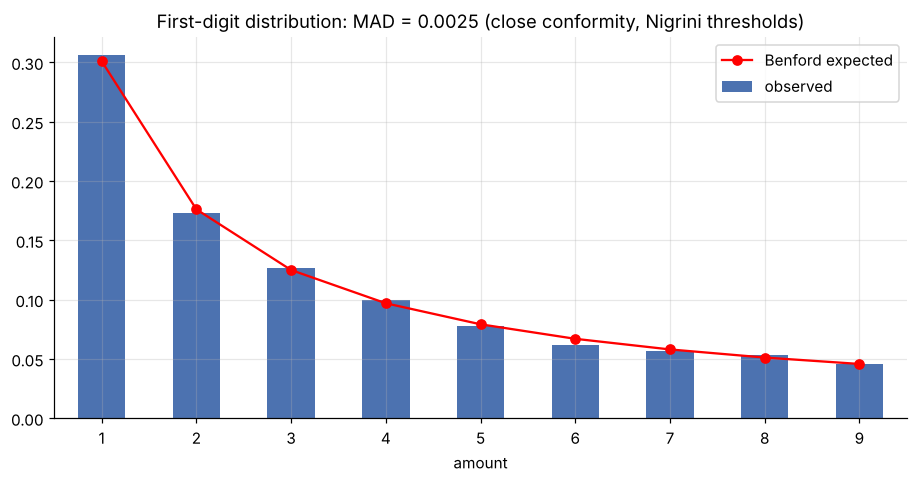

Largest excess digits: {1: 0.005, 4: 0.003, 8: 0.002}


In [2]:
first = gl.amount.astype(str).str.lstrip("0.").str[0].astype(int)
obs = first.value_counts(normalize=True).sort_index()
exp = pd.Series(np.log10(1 + 1 / np.arange(1, 10)), index=range(1, 10))
mad = (obs - exp).abs().mean()
verdict = "close conformity" if mad < 0.006 else "acceptable" if mad < 0.012 else "marginal" if mad < 0.015 else "nonconformity"
ax = obs.plot.bar(color="#4C72B0", label="observed", rot=0); ax.plot(range(9), exp.values, "ro-", label="Benford expected")
ax.set_title(f"First-digit distribution: MAD = {mad:.4f} ({verdict}, Nigrini thresholds)"); ax.legend(); plt.savefig(IMG / "benford.png", bbox_inches="tight"); plt.show()
exc = (obs - exp).sort_values(ascending=False).head(3).round(3); print("Largest excess digits:", exc.to_dict())

## 2. Rule-based red flags

In [3]:
pair_freq = gl.groupby(["debit_acct", "credit_acct"]).je_id.transform("size")
user_freq = gl.user.map(gl.user.value_counts(normalize=True))
key = ["posting_date", "debit_acct", "credit_acct", "amount"]
flags = pd.DataFrame({
    "weekend": gl.posting_date.dt.weekday >= 5,
    "round_amount": (gl.amount >= 1000) & (gl.amount % 1000 == 0),
    "below_threshold": gl.amount.between(9500, 9999.99),
    "after_hours": (gl.hour >= 21) | (gl.hour <= 5),
    "rare_user": user_freq < 0.01,
    "rare_account_pair": pair_freq < 30,
    "suspense_account": (gl.debit_acct == "6900") | (gl.credit_acct == "6900"),
    "duplicate": gl.duplicated(key, keep=False),
})
summary = pd.DataFrame({"entries flagged": flags.sum(), "of which planted anomalies": flags[truth.values].sum()})
summary["precision"] = summary["of which planted anomalies"] / summary["entries flagged"]
summary.style.format({"precision": "{:.0%}"})

,entries flagged,of which planted anomalies,precision
weekend,25,25,100%
round_amount,25,25,100%
below_threshold,107,26,24%
after_hours,20,20,100%
rare_user,20,20,100%
rare_account_pair,35,35,100%
suspense_account,15,15,100%
duplicate,30,15,50%


## 3. Anomaly detection and risk scoring

In [4]:
feat = pd.DataFrame({"log_amount": np.log(gl.amount), "hour": gl.hour, "weekday": gl.posting_date.dt.weekday,
                     "pair_rarity": -np.log(pair_freq / len(gl)), "user_rarity": -np.log(user_freq),
                     "roundness": (gl.amount % 100 == 0).astype(int) + (gl.amount % 1000 == 0).astype(int)})
iso = IsolationForest(n_estimators=400, contamination=0.02, random_state=0).fit(feat)
gl["iso_score"] = -iso.score_samples(feat)
weights = {"weekend": 2, "round_amount": 1.5, "below_threshold": 2, "after_hours": 2, "rare_user": 2, "rare_account_pair": 1.5, "suspense_account": 2, "duplicate": 3}
# rule flags drive the score; the anomaly model adds up to 1 point and breaks ties among entries with the same flags
gl["risk_score"] = (flags * pd.Series(weights)).sum(axis=1) + gl.iso_score.rank(pct=True)
top = gl.sort_values("risk_score", ascending=False)
k = int(flags.any(axis=1).sum())                         # review every entry with at least one red flag
hit = truth.loc[top.index[:k]].mean(); recall = truth.loc[top.index[:k]].sum() / truth.sum()
print(f"Reviewing the {k} flagged entries ({k / len(gl):.1%} of the ledger) catches {recall:.0%} of planted anomalies (precision {hit:.0%}).")
print(f"A random sample of the same size would catch about {k / len(gl):.1%} of them.")
iso_only = truth.loc[gl.sort_values("iso_score", ascending=False).index[:k]].sum() / truth.sum()
print(f"The Isolation Forest alone, at the same review budget, finds {iso_only:.0%}: useful as a second opinion, weaker than domain rules.")
top.head(10)[["je_id", "posting_date", "hour", "debit_acct", "credit_acct", "amount", "user", "risk_score"]]

Reviewing the 221 flagged entries (1.8% of the ledger) catches 100% of planted anomalies (precision 57%).
A random sample of the same size would catch about 1.8% of them.
The Isolation Forest alone, at the same review budget, finds 34%: useful as a second opinion, weaker than domain rules.


,je_id,posting_date,hour,debit_acct,credit_acct,amount,user,risk_score
1567,1568,2025-01-20,23,6400,1000,205.93,cfo_admin,6.500000
9024,9025,2025-03-25,0,6400,1000,130.25,cfo_admin,6.499917
7295,7296,2025-08-21,22,6400,1000,120.10,cfo_admin,6.499834
8936,8937,2025-07-11,0,6400,1000,18099.63,cfo_admin,6.499750
5959,5960,2025-10-21,23,6400,1000,243.10,cfo_admin,6.499667
2218,2219,2025-01-27,0,6400,1000,8316.01,cfo_admin,6.499584
3264,3265,2025-10-20,22,6400,1000,5846.44,cfo_admin,6.499501
5924,5925,2025-01-22,1,6400,1000,344.09,cfo_admin,6.499417
6730,6731,2025-09-25,1,6400,1000,386.37,cfo_admin,6.499334
2217,2218,2025-06-23,1,6400,1000,2289.30,cfo_admin,6.499251


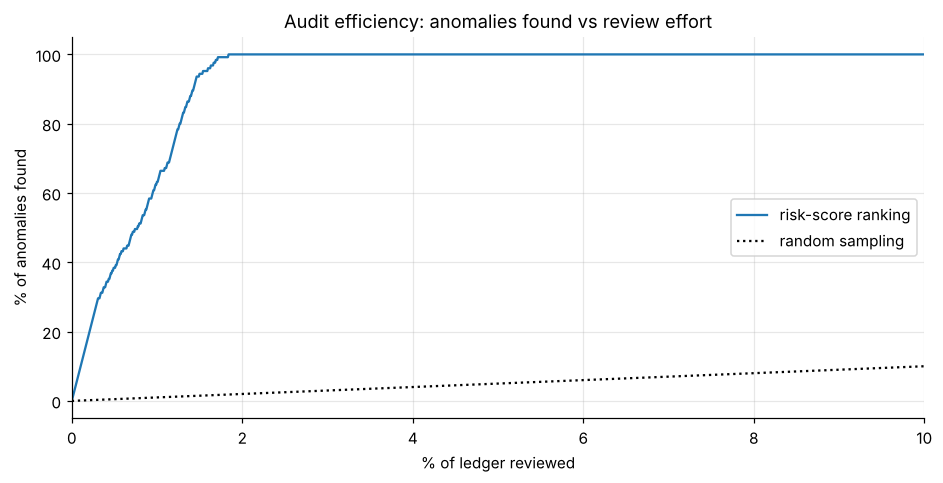

In [5]:
recall_curve = truth.loc[top.index].cumsum().values / truth.sum()
plt.plot(np.arange(1, len(gl) + 1) / len(gl) * 100, recall_curve * 100, label="risk-score ranking")
plt.plot([0, 100], [0, 100], "k:", label="random sampling"); plt.xlim(0, 10)
plt.xlabel("% of ledger reviewed"); plt.ylabel("% of anomalies found"); plt.title("Audit efficiency: anomalies found vs review effort"); plt.legend()
plt.savefig(IMG / "audit_efficiency.png", bbox_inches="tight"); plt.show()

**Takeaways for audit and finance teams**
* Full-population testing replaces sampling. Every posting is scored, and reviewers start with the riskiest few percent.
* Benford's law is a useful first screen of a whole ledger, but here the ledger conforms overall while still containing planted fraud. Round and just-below-threshold amounts are caught by **targeted rules**, not by first-digit tests.
* Domain rules are precise and explainable. The unsupervised model is weaker on its own but ranks entries *within* each flag group, so reviewers see the strangest cases first. The threshold rule shows why audit judgement still matters: genuine invoices also fall in the $9,500-9,999 band.
* The same notebook runs on any ERP export (SAP, Oracle, QuickBooks, Dynamics) once columns are mapped to `posting_date, hour, debit_acct, credit_acct, amount, user`.